# Paso 5 — Recreación del análisis
**Artículo:** Wang, Xu & Zhou (2015). Se recrean LLRE (propuesto), Random Forest, Lasso-logística (LLR) y CART, evaluados con AUC y F-measure sobre dos conjuntos de variables: originales y derivadas.

El código reutilizable está en `src/` (`features.py`, `llre.py`, `evaluate.py`); este notebook lo ejecuta e interpreta los resultados.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, f1_score

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from features import FeatureBuilder
from llre import LLRE
from evaluate import una_corrida, correr_experimento

TARGET = "SeriousDlqin2yrs"
MUESTRA = None      # None usa todos los registros; un entero usa una muestra (pruebas rápidas)
(RAIZ / "results").mkdir(exist_ok=True); (RAIZ / "figures").mkdir(exist_ok=True)

## 5.1 Datos y partición 80/20
El artículo usa una partición aleatoria 80 % / 20 %. La imputación, el escalado y el clustering se ajustan solo con el conjunto de entrenamiento.

In [2]:
df = pd.read_csv(RAIZ / "data" / "datos_simulados.csv")
if MUESTRA:
    df = df.sample(MUESTRA, random_state=0)
train, test = train_test_split(df, test_size=0.2, random_state=1000)
y_tr, y_te = train[TARGET].values, test[TARGET].values
print("train:", train.shape, " test:", test.shape)
print(f"Porcentaje de clase 1 -> train: {y_tr.mean()*100:.2f}%   test: {y_te.mean()*100:.2f}%")

train: (120000, 11)  test: (30000, 11)
Porcentaje de clase 1 -> train: 6.74%   test: 6.45%


## 5.2 Variables originales y derivadas
El artículo genera las variables derivadas con tres técnicas: transformación `log(x+1)`, banderas para NA y códigos especiales, y *binning*. Para `age` da la fórmula exacta (Ec. 9). El artículo no lista sus 80 variables; el conjunto usado aquí es una reconstrucción con esas técnicas y con los nombres que el artículo menciona (README, sección 3.3).

In [3]:
fb_orig = FeatureBuilder("original")
Xo_tr, Xo_te = fb_orig.fit_transform(train), fb_orig.transform(test)

fb_der = FeatureBuilder("derived")
Xd_tr, Xd_te = fb_der.fit_transform(train), fb_der.transform(test)
print("originales:", Xo_tr.shape[1], "columnas  |  derivadas (incluye las originales):", Xd_tr.shape[1])
pd.Series(Xd_tr.columns[10:], name="variables derivadas creadas").to_frame()

originales: 10 columnas  |  derivadas (incluye las originales): 56


,variables derivadas creadas
0,MonthlyIncome_NA
1,NumberOfDependents_NA
2,SpecialCodePastDue
3,NeverPastDue30_59
4,NeverLate90
5,NeverPastDue60_89
6,NeverPastDue
7,ExcessUtilization
8,HasRevolvingLines
9,NumberOfTimesPastDue


In [4]:
# Ejemplo concreto: las tres variables que el artículo destaca como más importantes
Xd_tr[["NeverPastDue", "DisposableIncome", "LogRevolvingUtilizationTimesLines", "SpecialCodePastDue"]].describe().round(3)

,NeverPastDue,DisposableIncome,LogRevolvingUtilizationTimesLines,SpecialCodePastDue
count,120000.000,120000.000,120000.000,120000.000
mean,0.743,360.175,0.862,0.002
std,0.437,8612.368,0.632,0.042
min,0.000,-615157.551,0.000,0.000
25%,0.000,-239.870,0.309,0.000
50%,1.000,1485.565,0.786,0.000
75%,1.000,3108.689,1.326,0.000
max,1.000,62772.566,4.105,1.000


## 5.3 LLRE paso a paso (variables derivadas)
El LLRE (1) agrupa la clase mayoritaria en k = 14 subgrupos con K-means; (2) combina cada subgrupo con una muestra *bootstrap* de la clase minoritaria, formando un conjunto balanceado (BS); (3) entrena un Lasso-logístico por conjunto y elige λ según el AUC sobre OBS, los datos de entrenamiento que no están en BS; (4) combina los modelos con pesos `w = 1/(1+e^(-AUC))` (Ec. 4).

Con los 150.000 registros, el entrenamiento tarda entre 1 y 3 minutos.

In [5]:
sc = StandardScaler().fit(Xd_tr)
Xs_tr, Xs_te = sc.transform(Xd_tr), sc.transform(Xd_te)

t0 = time.time()
llre = LLRE(k=14, n_jobs=2, random_state=1000).fit(Xs_tr, y_tr)
print(f"entrenado en {time.time()-t0:.0f} s; modelos base conservados: {len(llre.pesos_)} (= ceil(0.75*14))")
llre.resumen_base()

entrenado en 9 s; modelos base conservados: 11 (= ceil(0.75*14))


,subgrupo,n_mayoritaria,lambda,pos_rejilla,AUC_OBS,peso,vars_no_cero
0,7,14992,626.5334,3,0.8679,0.7043,5
1,9,11839,4336.8596,1,0.8903,0.7089,1
2,8,10675,473.7557,2,0.7100,0.6704,15
3,1,9802,477.8336,3,0.8297,0.6963,8
4,2,9666,65.5191,5,0.8789,0.7066,19
5,3,9534,487.1694,3,0.8373,0.6979,11
6,6,8904,529.5278,3,0.8832,0.7075,7
7,4,8523,516.2844,3,0.8879,0.7085,7
8,10,6170,3617.5171,1,0.8839,0.7076,3
9,13,6078,1410.5646,2,0.9057,0.7121,5


Tabla de modelos base: `n_mayoritaria` es el tamaño del subgrupo; `lambda`, la penalización elegida; `pos_rejilla`, la posición de ese λ en la rejilla (0 = más penalizado; un valor en el último extremo indicaría una rejilla demasiado corta); `AUC_OBS`, el desempeño sobre datos que el modelo no vio; `peso`, `1/(1+e^(-AUC))`, que varía poco y evita que un modelo domine; `vars_no_cero`, el número de variables que conserva el Lasso.

In [6]:
proba = llre.predict_proba(Xs_te)
print("LLRE (derivadas)  AUC = %.4f   F1 = %.4f" % (roc_auc_score(y_te, proba), f1_score(y_te, proba >= 0.5)))

LLRE (derivadas)  AUC = 0.9198   F1 = 0.3337


In [7]:
# Importancia por ocurrencia (Ec. 5): en cuántos de los modelos base la variable tiene coeficiente != 0
occ = pd.Series(llre.importancia_ocurrencia(Xd_tr.columns))
print("máximo posible =", len(llre.pesos_))
occ.head(15).to_frame("ocurrencias")

máximo posible = 11


,ocurrencias
LogNumberOfTimesPastDue,8
NumberOfTimesPastDue,7
LogRevolvingUtilizationOfUnsecuredLines,6
LogDebtRatio,6
RevolvingUtilizationOfUnsecuredLines_bin0,6
SeniorAge,5
NeverPastDue,4
DebtRatio_bin4,4
NumberOfOpenCreditLinesAndLoans,3
NeverLate90,3


## 5.4 Comparación de los cuatro clasificadores en una corrida
Configuración reportada: RF con 500 árboles y `mtry = 3`; CART con criterio Gini; LLR con AUC como criterio de selección; LLRE con k = 14. Se ejecuta una corrida (partición aleatoria nueva) con ambos conjuntos de variables.

In [8]:
t0 = time.time()
filas = una_corrida(df, "original", run=0) + una_corrida(df, "derived", run=0)
una = pd.DataFrame(filas)
print(f"{time.time()-t0:.0f} s")
una.pivot(index="clasificador", columns="variables", values=["auc", "f1"]).round(4)

330 s


auc               f1         
variables    derived original derived original
clasificador                                  
CART          0.8983   0.8538  0.6549   0.5850
LLR           0.9357   0.7326  0.6401   0.1035
LLRE          0.9200   0.9180  0.3343   0.1578
RF            0.9255   0.9235  0.6365   0.6294

## 5.5 Corridas repetidas
El artículo promedia 30 corridas. `N_RUNS` controla el número de corridas; los resultados se guardan de forma incremental en `results/paso5_resultados_por_corrida.csv` y, si la ejecución se interrumpe, se retoma donde quedó. El número de corridas usado debe indicarse al reportar los resultados.

In [9]:
N_RUNS = 3          # número de corridas (el artículo usa 30)
res = correr_experimento(df, n_runs=N_RUNS, destino=RAIZ / "results" / "paso5_resultados_por_corrida.csv")
res.shape

(24, 9)

In [10]:
resumen = (res.groupby(["clasificador", "variables"])[["auc", "f1"]]
              .agg(["mean", "std"]).round(4))
resumen.columns = [f"{m}_{s}" for m, s in resumen.columns]     # encabezado de una sola fila
resumen.to_csv(RAIZ / "results" / "paso5_resumen.csv")
resumen

auc_mean  auc_std  f1_mean  f1_std
clasificador variables                                    
CART         derived      0.8948   0.0037   0.6531  0.0115
             original     0.8565   0.0075   0.6086  0.0234
LLR          derived      0.9349   0.0033   0.6462  0.0092
             original     0.7339   0.0022   0.1002  0.0059
LLRE         derived      0.9183   0.0031   0.3326  0.0099
             original     0.9179   0.0041   0.1537  0.0045
RF           derived      0.9259   0.0035   0.6437  0.0114
             original     0.9251   0.0036   0.6377  0.0106

In [11]:
# Posición del lambda elegido en la rejilla (0 = más penalizado). Un valor pegado al máximo
# de la rejilla (n_rejilla - 1) indicaría que la rejilla quedó corta.
(res.groupby(["clasificador", "variables"])[["pos_rejilla", "n_rejilla"]].mean().dropna().round(2))

pos_rejilla  n_rejilla
clasificador variables                        
LLR          derived           8.67       10.0
             original          6.00       10.0
LLRE         derived           2.42       30.0
             original         13.45       30.0

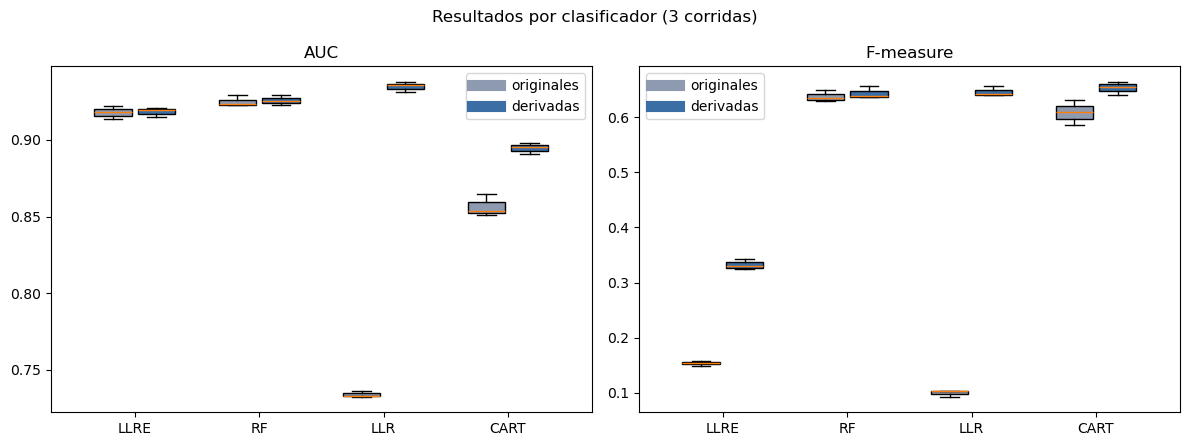

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
orden = ["LLRE", "RF", "LLR", "CART"]
for ax, met, tit in zip(axes, ["auc", "f1"], ["AUC", "F-measure"]):
    for j, (modo, col) in enumerate([("original", "#8e9aaf"), ("derived", "#3b6ea5")]):
        datos = [res[(res.clasificador == c) & (res.variables == modo)][met] for c in orden]
        pos = np.arange(len(orden)) + (j - 0.5) * 0.35
        bp = ax.boxplot(datos, positions=pos, widths=0.3, patch_artist=True)
        for b in bp["boxes"]: b.set_facecolor(col)
        ax.plot([], [], color=col, lw=8, label="originales" if modo == "original" else "derivadas")
    ax.set_xticks(range(len(orden))); ax.set_xticklabels(orden); ax.set_title(tit); ax.legend()
fig.suptitle(f"Resultados por clasificador ({res.run.nunique()} corridas)")
fig.tight_layout()
fig.savefig(RAIZ / "figures" / "paso5_resultados_por_clasificador.png", dpi=130)

## 5.6 Lectura de resultados
Patrones que se contrastan con el artículo en el Paso 6:
- Mejora del Lasso-logístico (LLR) al pasar de variables originales a derivadas (artículo: 0,4898 → 0,8567).
- F-measure de CART cercano a 0 (artículo: 0 en las 30 corridas).
- F-measure del LLRE frente a los demás clasificadores (artículo: ≈ 0,37–0,41 frente a ≈ 0,26–0,30 de RF).

Los valores absolutos no tienen por qué coincidir con los del artículo, porque la intensidad de la señal en los datos simulados es un supuesto; se comparan los patrones.

## 5.7 Análisis complementario: umbral de decisión del LLRE
En los resultados del Paso 5 el LLRE tiene un AUC similar al del RF y al del LLR, pero un F-measure mucho menor. Como el AUC no depende del umbral, la diferencia sugiere un problema de calibración: el LLRE se entrena con conjuntos balanceados (cerca de 50 % de clase 1), de modo que sus probabilidades sobreestiman el riesgo respecto de la prevalencia real (6,7 %) y, con el umbral de 0,5, marca como morosos a demasiados clientes.

Este análisis **no forma parte del artículo**; se agrega para explicar la diferencia. Sobre el LLRE con variables derivadas ajustado en la sección 5.3 se comparan tres reglas de decisión: (a) umbral de 0,5, como en el artículo; (b) probabilidades corregidas por el cambio de prevalencia, con la prevalencia del entrenamiento (no se usa información de prueba); (c) el mejor umbral posible sobre el conjunto de prueba, que es una cota superior y no una regla utilizable.

In [13]:
from sklearn.metrics import precision_score, recall_score

prior = y_tr.mean()
p_05 = llre.predict_proba(Xs_te)
p_corr = llre.predict_proba_corregido(Xs_te, prior)

umbrales = np.linspace(0.02, 0.98, 97)
f1_u = [f1_score(y_te, p_05 >= u) for u in umbrales]
u_best = umbrales[int(np.argmax(f1_u))]

def fila(nombre, p, u):
    pred = (p >= u).astype(int)
    return {"regla": nombre, "umbral": round(float(u), 2), "n_pred_pos": int(pred.sum()),
            "precision": round(precision_score(y_te, pred), 3), "recall": round(recall_score(y_te, pred), 3),
            "F1": round(f1_score(y_te, pred), 3)}

tabla = pd.DataFrame([
    fila("(a) umbral 0,5 (artículo)", p_05, 0.5),
    fila("(b) probabilidades corregidas por prevalencia", p_corr, 0.5),
    fila("(c) mejor umbral en prueba (cota superior)", p_05, u_best),
])
print("clientes de prueba:", len(y_te), "| morosos reales:", int(y_te.sum()), "| prevalencia en entrenamiento: %.3f" % prior)
tabla.to_csv(RAIZ / "results" / "paso5_umbral_llre.csv", index=False)
tabla

clientes de prueba: 30000 | morosos reales: 1934 | prevalencia en entrenamiento: 0.067


,regla,umbral,n_pred_pos,precision,recall,F1
0,"(a) umbral 0,5 (artículo)",0.50,8460,0.205,0.897,0.334
1,(b) probabilidades corregidas por prevalencia,0.50,590,0.964,0.294,0.451
2,(c) mejor umbral en prueba (cota superior),0.83,1766,0.680,0.620,0.649
